In [16]:
"""
H&M Consumer Behavior Analysis
Notebook 01: Exploratory Data Analysis (EDA)

Purpose: Understand data quality, patterns, and initial insights
"""

# Core libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

# Plotting configuration
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("husl")
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11

%matplotlib inline
%config InlineBackend.figure_format = 'retina'

# Pandas display options
pd.set_option('display.max_columns', 50)
pd.set_option('display.max_rows', 100)
pd.set_option('display.float_format', '{:.2f}'.format)

print("="*70)
print("H&M CONSUMER BEHAVIOR - EXPLORATORY DATA ANALYSIS")
print("="*70)
print(f"\n Libraries loaded successfully")

H&M CONSUMER BEHAVIOR - EXPLORATORY DATA ANALYSIS

 Libraries loaded successfully


In [17]:
import sys
!{sys.executable} -m pip install pyarrow

In [18]:
import os
print(os.listdir("../data"))

['features', 'processed', 'raw']


In [19]:
# ============================================================
# DATA LOADING & PROJECT PATH SETUP
# ============================================================

from pathlib import Path

# Define paths (Notebook is inside /notebooks folder)
DATA_PATH = Path("../data/processed")
FIGURES_PATH = Path("../reports/figures")
TABLES_PATH = Path("../reports/tables")

# Create output directories if they don't exist
FIGURES_PATH.mkdir(parents=True, exist_ok=True)
TABLES_PATH.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# Load processed 10% dataset (CSV version)
# ------------------------------------------------------------

print("\n Loading H&M 10% processed sample...")

df = pd.read_csv("transactions_train.csv", parse_dates=["t_dat"])


print("\n Data loaded successfully!")
print("="*60)
print(" DATASET OVERVIEW")
print("="*60)

print(f"Shape: {df.shape[0]:,} rows × {df.shape[1]} columns")
print(f"Memory Usage: {df.memory_usage(deep=True).sum() / 1024**2:.2f} MB")
print(f"Date Range: {df['t_dat'].min()} → {df['t_dat'].max()}")
print(f"Unique Customers: {df['customer_id'].nunique():,}")
print(f"Unique Articles: {df['article_id'].nunique():,}")
print(f"Total Revenue: {df['price'].sum():,.2f}")

print("\n Sample Data:")
display(df.head())


 Loading H&M 10% processed sample...

 Data loaded successfully!
 DATASET OVERVIEW
Shape: 31,788,324 rows × 5 columns
Memory Usage: 4395.78 MB
Date Range: 2018-09-20 00:00:00 → 2020-09-22 00:00:00
Unique Customers: 1,362,281
Unique Articles: 104,547
Total Revenue: 884,645.97

 Sample Data:


,t_dat,customer_id,article_id,price,sales_channel_id
0,2018-09-20,000058a12d5b43e67d225668fa1f8d618c13dc232df0ca...,663713001,0.05,2
1,2018-09-20,000058a12d5b43e67d225668fa1f8d618c13dc232df0ca...,541518023,0.03,2
2,2018-09-20,00007d2de826758b65a93dd24ce629ed66842531df6699...,505221004,0.02,2
3,2018-09-20,00007d2de826758b65a93dd24ce629ed66842531df6699...,685687003,0.02,2
4,2018-09-20,00007d2de826758b65a93dd24ce629ed66842531df6699...,685687004,0.02,2


In [20]:
# Display first rows
print("\n First 10 Rows:")
display(df.head(10))

print("\n Last 10 Rows:")
display(df.tail(10))

print("\n Random Sample (10 rows):")
display(df.sample(10, random_state=42))


 First 10 Rows:


,t_dat,customer_id,article_id,price,sales_channel_id
0,2018-09-20,000058a12d5b43e67d225668fa1f8d618c13dc232df0ca...,663713001,0.05,2
1,2018-09-20,000058a12d5b43e67d225668fa1f8d618c13dc232df0ca...,541518023,0.03,2
2,2018-09-20,00007d2de826758b65a93dd24ce629ed66842531df6699...,505221004,0.02,2
3,2018-09-20,00007d2de826758b65a93dd24ce629ed66842531df6699...,685687003,0.02,2
4,2018-09-20,00007d2de826758b65a93dd24ce629ed66842531df6699...,685687004,0.02,2
5,2018-09-20,00007d2de826758b65a93dd24ce629ed66842531df6699...,685687001,0.02,2
6,2018-09-20,00007d2de826758b65a93dd24ce629ed66842531df6699...,505221001,0.02,2
7,2018-09-20,00083cda041544b2fbb0e0d2905ad17da7cf1007526fb4...,688873012,0.03,1
8,2018-09-20,00083cda041544b2fbb0e0d2905ad17da7cf1007526fb4...,501323011,0.05,1
9,2018-09-20,00083cda041544b2fbb0e0d2905ad17da7cf1007526fb4...,598859003,0.05,2



 Last 10 Rows:


,t_dat,customer_id,article_id,price,sales_channel_id
31788314,2020-09-22,ffd4cf2217de4a0a3f9f610cdec334c803692a18af08ac...,701472004,0.01,2
31788315,2020-09-22,ffd4cf2217de4a0a3f9f610cdec334c803692a18af08ac...,456163087,0.03,2
31788316,2020-09-22,ffd4cf2217de4a0a3f9f610cdec334c803692a18af08ac...,832505003,0.03,2
31788317,2020-09-22,ffd4cf2217de4a0a3f9f610cdec334c803692a18af08ac...,902288001,0.02,2
31788318,2020-09-22,ffd4cf2217de4a0a3f9f610cdec334c803692a18af08ac...,856440002,0.04,2
31788319,2020-09-22,fff2282977442e327b45d8c89afde25617d00124d0f999...,929511001,0.06,2
31788320,2020-09-22,fff2282977442e327b45d8c89afde25617d00124d0f999...,891322004,0.04,2
31788321,2020-09-22,fff380805474b287b05cb2a7507b9a013482f7dd0bce0e...,918325001,0.04,1
31788322,2020-09-22,fff4d3a8b1f3b60af93e78c30a7cb4cf75edaf2590d3e5...,833459002,0.01,1
31788323,2020-09-22,fffef3b6b73545df065b521e19f64bf6fe93bfd450ab20...,898573003,0.03,2



 Random Sample (10 rows):


,t_dat,customer_id,article_id,price,sales_channel_id
16558544,2019-09-13,215895f90002eb3d1a04bd603513c8e85e6002ef08f136...,786586001,0.02,1
6583409,2019-02-23,7b183268e3a4623b80d5325ec4a20a0af0edff7bcb1748...,658911001,0.03,2
13976622,2019-07-17,2eb7412239a90c0570cd3d1bf0492856ae5b59058b1ea6...,759326005,0.05,2
10327778,2019-05-16,74f162e5a170fd57207aa2a7d5c58479ee9de903b2a277...,737137004,0.03,1
15285658,2019-08-10,aab9306ee28c4db494003955f80355e540b01480ab35cf...,785931001,0.05,2
18644287,2019-11-04,01dd96059a11759518f10969d0a528f03c8501dc4c628b...,771829002,0.07,2
12469016,2019-06-23,b20cd1499a96282af3adb57387a52de74c01062c479ae7...,663282007,0.04,2
26122348,2020-05-22,9cc3a0a2e13b8c7796ea7e597128d28de2f4a75b1dad55...,464297007,0.01,1
7481543,2019-03-17,436e0ab4fd13bfc291cf4278121a474bcc7258a5b3d70f...,781683004,0.04,2
29320136,2020-07-22,1ca8c524df4c6a76fdc80f860228a349f78c9c19508978...,865917001,0.02,1


In [21]:
print(df.columns.tolist())


['t_dat', 'customer_id', 'article_id', 'price', 'sales_channel_id']


In [22]:
# Data types and info
print("\n Column Information:")
print("\n")
df.info()

print("\n Column Types Summary:")
print(df.dtypes.value_counts())




 Column Information:


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 31788324 entries, 0 to 31788323
Data columns (total 5 columns):
 #   Column            Dtype         
---  ------            -----         
 0   t_dat             datetime64[ns]
 1   customer_id       object        
 2   article_id        int64         
 3   price             float64       
 4   sales_channel_id  int64         
dtypes: datetime64[ns](1), float64(1), int64(2), object(1)
memory usage: 1.2+ GB

 Column Types Summary:
int64             2
datetime64[ns]    1
object            1
float64           1
Name: count, dtype: int64


In [ ]:
# ============================================================
# DATA QUALITY ASSESSMENT
# ============================================================

print("\n DATA QUALITY ASSESSMENT")
print("="*70)

# ----------------------------
# 1️ Missing Values
# ----------------------------

missing = df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)

if len(missing) > 0:
    missing_pct = (missing / len(df) * 100).round(2)

    missing_df = pd.DataFrame({
        'Missing_Count': missing,
        'Percentage (%)': missing_pct,
        'Data_Type': df[missing.index].dtypes
    })

    print("\n⚠️ Missing Values Found:\n")
    display(missing_df)

    # Visualize missing data
    plt.figure(figsize=(10, 6))
    missing_pct.sort_values().plot(kind='barh', color='coral')
    plt.xlabel('Percentage Missing (%)')
    plt.title('Missing Data by Column', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.savefig(FIGURES_PATH / 'missing_data_analysis.png', dpi=300)
    plt.show()

else:
    print("\n No missing values detected!")

# ----------------------------
# 2️ Duplicate Rows
# ----------------------------

duplicates = df.duplicated().sum()
dup_pct = round(duplicates / len(df) * 100, 4)

print("\n Duplicate Rows:")
print(f"   Count: {duplicates:,}")
print(f"   Percentage: {dup_pct}%")

# ----------------------------
# 3️ Data Type Validation
# ----------------------------

print("\n Data Type Validation:")

print(f"    t_dat is datetime: {pd.api.types.is_datetime64_any_dtype(df['t_dat'])}")
print(f"    price is numeric: {pd.api.types.is_numeric_dtype(df['price'])}")
print(f"    customer_id is object/string: {df['customer_id'].dtype == 'object'}")

# ----------------------------
# 4️ Basic Integrity Checks
# ----------------------------

print("\n Basic Integrity Checks:")

print(f"   Negative prices present: {(df['price'] < 0).sum()}")
print(f"   Zero prices present: {(df['price'] == 0).sum()}")
print(f"   Unique customers: {df['customer_id'].nunique():,}")
print(f"   Unique products: {df['article_id'].nunique():,}")


 DATA QUALITY ASSESSMENT



 No missing values detected!

 Duplicate Rows:
   Count: 2,974,905
   Percentage: 9.3585%

 Data Type Validation:
    t_dat is datetime: True
    price is numeric: True
    customer_id is object/string: True

 Basic Integrity Checks:
   Negative prices present: 0
   Zero prices present: 0
   Unique customers: 1,362,281
   Unique products: 104,547


In [24]:
df[df.duplicated()].head()
df[df.duplicated()].shape

(2974905, 5)

In [25]:
duplicate_rows = df[df.duplicated(keep=False)]
duplicate_rows.head()

,t_dat,customer_id,article_id,price,sales_channel_id
14,2018-09-20,000aa7f0dc06cd7174389e76c9e132a67860c5f65f9706...,501820043,0.02,2
15,2018-09-20,000aa7f0dc06cd7174389e76c9e132a67860c5f65f9706...,501820043,0.02,2
17,2018-09-20,000aa7f0dc06cd7174389e76c9e132a67860c5f65f9706...,671505001,0.03,2
18,2018-09-20,000aa7f0dc06cd7174389e76c9e132a67860c5f65f9706...,671505001,0.03,2
19,2018-09-20,000aa7f0dc06cd7174389e76c9e132a67860c5f65f9706...,631848002,0.03,2


In [26]:
duplicate_rows = df[df.duplicated(keep=False)]
duplicate_rows.sort_values(
    by=["customer_id", "article_id", "t_dat"]
).head(20)

,t_dat,customer_id,article_id,price,sales_channel_id
10754876,2019-05-25,00000dbacae5abe5e23885899a1fa44253a17956c6d1c3...,568601006,0.05,2
10754877,2019-05-25,00000dbacae5abe5e23885899a1fa44253a17956c6d1c3...,568601006,0.05,2
17074660,2019-09-28,00000dbacae5abe5e23885899a1fa44253a17956c6d1c3...,797065001,0.05,2
17074661,2019-09-28,00000dbacae5abe5e23885899a1fa44253a17956c6d1c3...,797065001,0.05,2
24902751,2020-04-22,0000423b00ade91418cceaf3b26c6af3dd342b51fd051e...,599580055,0.02,2
24902752,2020-04-22,0000423b00ade91418cceaf3b26c6af3dd342b51fd051e...,599580055,0.02,2
13329244,2019-07-05,0000423b00ade91418cceaf3b26c6af3dd342b51fd051e...,689898002,0.01,2
13329245,2019-07-05,0000423b00ade91418cceaf3b26c6af3dd342b51fd051e...,689898002,0.01,2
21485436,2020-01-21,0000423b00ade91418cceaf3b26c6af3dd342b51fd051e...,739590027,0.02,2
21485437,2020-01-21,0000423b00ade91418cceaf3b26c6af3dd342b51fd051e...,739590027,0.02,2


In [27]:
# ============================================================
# NUMERICAL SUMMARY ANALYSIS
# ============================================================

print("\n NUMERICAL STATISTICS")
print("="*70)

# ----------------------------
# 1️ Identify numerical columns
# ----------------------------

numerical_cols = df.select_dtypes(include=[np.number]).columns.tolist()
print(f"\nNumerical columns detected:\n{numerical_cols}\n")

display(df[numerical_cols].describe())

# ----------------------------
# 2️ Price Distribution Analysis
# ----------------------------

print("\n PRICE DISTRIBUTION ANALYSIS")
print("-"*70)

price_stats = {
    "Min": df['price'].min(),
    "25th Percentile": df['price'].quantile(0.25),
    "Median": df['price'].median(),
    "Mean": df['price'].mean(),
    "75th Percentile": df['price'].quantile(0.75),
    "Max": df['price'].max(),
    "Std Dev": df['price'].std()
}

for k, v in price_stats.items():
    print(f"{k:<18}: ${v:.2f}")

# Skewness check
skewness = df['price'].skew()
print(f"\nPrice Skewness: {skewness:.2f}")

if skewness > 1:
    print("   Highly right-skewed (typical retail pattern)")
elif skewness > 0:
    print("   Moderately right-skewed")
else:
    print("   Symmetric or left-skewed")

# ----------------------------
# 3️ Age Distribution
# ----------------------------

if 'age' in df.columns:
    age_data = df[df['age'].notna()]
    
    print("\n AGE DISTRIBUTION ANALYSIS")
    print("-"*70)
    
    print(f"Min Age      : {age_data['age'].min():.0f} years")
    print(f"Median Age   : {age_data['age'].median():.0f} years")
    print(f"Mean Age     : {age_data['age'].mean():.1f} years")
    print(f"Max Age      : {age_data['age'].max():.0f} years")
    print(f"Data Coverage: {len(age_data)/len(df)*100:.1f}% of records")

    # Optional: check unrealistic ages
    unrealistic = age_data[(age_data['age'] < 10) | (age_data['age'] > 100)]
    print(f"Unrealistic age values: {len(unrealistic)}")


 NUMERICAL STATISTICS

Numerical columns detected:
['article_id', 'price', 'sales_channel_id']



,article_id,price,sales_channel_id
count,31788324.00,31788324.00,31788324.00
mean,696227219.13,0.03,1.70
std,133448003.49,0.02,0.46
min,108775015.00,0.00,1.00
25%,632803008.00,0.02,1.00
50%,714582003.00,0.03,2.00
75%,786524001.00,0.03,2.00
max,956217002.00,0.59,2.00



 PRICE DISTRIBUTION ANALYSIS
----------------------------------------------------------------------
Min               : $0.00
25th Percentile   : $0.02
Median            : $0.03
Mean              : $0.03
75th Percentile   : $0.03
Max               : $0.59
Std Dev           : $0.02

Price Skewness: 3.11
   Highly right-skewed (typical retail pattern)


In [28]:
# ============================================================
# CATEGORICAL VARIABLES ANALYSIS
# ============================================================

print("\n CATEGORICAL VARIABLES")
print("="*70)

categorical_cols = df.select_dtypes(include=['object', 'category']).columns.tolist()

print(f"\nTotal categorical columns detected: {len(categorical_cols)}\n")
print(categorical_cols)

for col in categorical_cols:
    
    n_unique = df[col].nunique()
    
    print("\n" + "-"*60)
    print(f" Column: {col}")
    print(f"Unique values: {n_unique:,}")
    
    # Missing percentage
    missing_pct = df[col].isnull().mean() * 100
    print(f"Missing: {missing_pct:.2f}%")
    
    # Low cardinality → show full distribution
    if n_unique <= 20:
        print("\nTop value distribution:")
        display(df[col].value_counts(normalize=True).head(10).round(4))
    
    # High cardinality → show only top 5
    else:
        print("\nTop 5 most frequent values:")
        display(df[col].value_counts().head(5))


 CATEGORICAL VARIABLES

Total categorical columns detected: 1

['customer_id']

------------------------------------------------------------
 Column: customer_id
Unique values: 1,362,281
Missing: 0.00%

Top 5 most frequent values:


customer_id
be1981ab818cf4ef6765b2ecaea7a2cbf14ccd6e8a7ee985513d9e8e53c6d91b    1895
b4db5e5259234574edfff958e170fe3a5e13b6f146752ca066abca3c156acc71    1441
49beaacac0c7801c2ce2d189efe525fe80b5d37e46ed05b50a4cd88e34d0748f    1364
a65f77281a528bf5c1e9f270141d601d116e1df33bf9df512f495ee06647a9cc    1361
cd04ec2726dd58a8c753e0d6423e57716fd9ebcf2f14ed6012e7e5bea016b4d6    1237
Name: count, dtype: int64

In [29]:
# Calculate key revenue metrics
total_revenue = df['price'].sum()
total_transactions = len(df)
avg_order_value = df['price'].mean()
num_customers = df['customer_id'].nunique()
num_products = df['article_id'].nunique()

print("\n REVENUE & TRANSACTION METRICS")
print("="*70)
print(f"\n Overall Metrics:")
print(f"   Total Revenue:           ${total_revenue:,.2f}")
print(f"   Total Transactions:      {total_transactions:,}")
print(f"   Average Order Value:     ${avg_order_value:.2f}")
print(f"   Unique Customers:        {num_customers:,}")
print(f"   Unique Products:         {num_products:,}")
print(f"\n Per-Customer Metrics:")
print(f"   Avg Transactions/Customer: {total_transactions/num_customers:.1f}")
print(f"   Avg Revenue/Customer:      ${total_revenue/num_customers:.2f}")

# Save summary table
summary_metrics = pd.DataFrame({
    'Metric': [
        'Total Revenue',
        'Total Transactions',
        'Average Order Value',
        'Unique Customers',
        'Unique Products',
        'Transactions per Customer',
        'Revenue per Customer'
    ],
    'Value': [
        f"${total_revenue:,.2f}",
        f"{total_transactions:,}",
        f"${avg_order_value:.2f}",
        f"{num_customers:,}",
        f"{num_products:,}",
        f"{total_transactions/num_customers:.1f}",
        f"${total_revenue/num_customers:.2f}"
    ]
})

summary_metrics.to_csv(TABLES_PATH / 'kpi_summary.csv', index=False)
print(f"\n Saved: reports/tables/kpi_summary.csv")


 REVENUE & TRANSACTION METRICS

 Overall Metrics:
   Total Revenue:           $884,645.97
   Total Transactions:      31,788,324
   Average Order Value:     $0.03
   Unique Customers:        1,362,281
   Unique Products:         104,547

 Per-Customer Metrics:
   Avg Transactions/Customer: 23.3
   Avg Revenue/Customer:      $0.65

 Saved: reports/tables/kpi_summary.csv



 TEMPORAL ANALYSIS

 Monthly Performance (First 5 months):


,revenue,unique_customers,transactions,month,avg_order_value
0,17755.64,140340,594776,2018-09-01,0.03
1,41584.82,274220,1397040,2018-10-01,0.03
2,39000.99,274207,1270619,2018-11-01,0.03
3,32532.51,254059,1148827,2018-12-01,0.03
4,33449.98,242024,1263471,2019-01-01,0.03


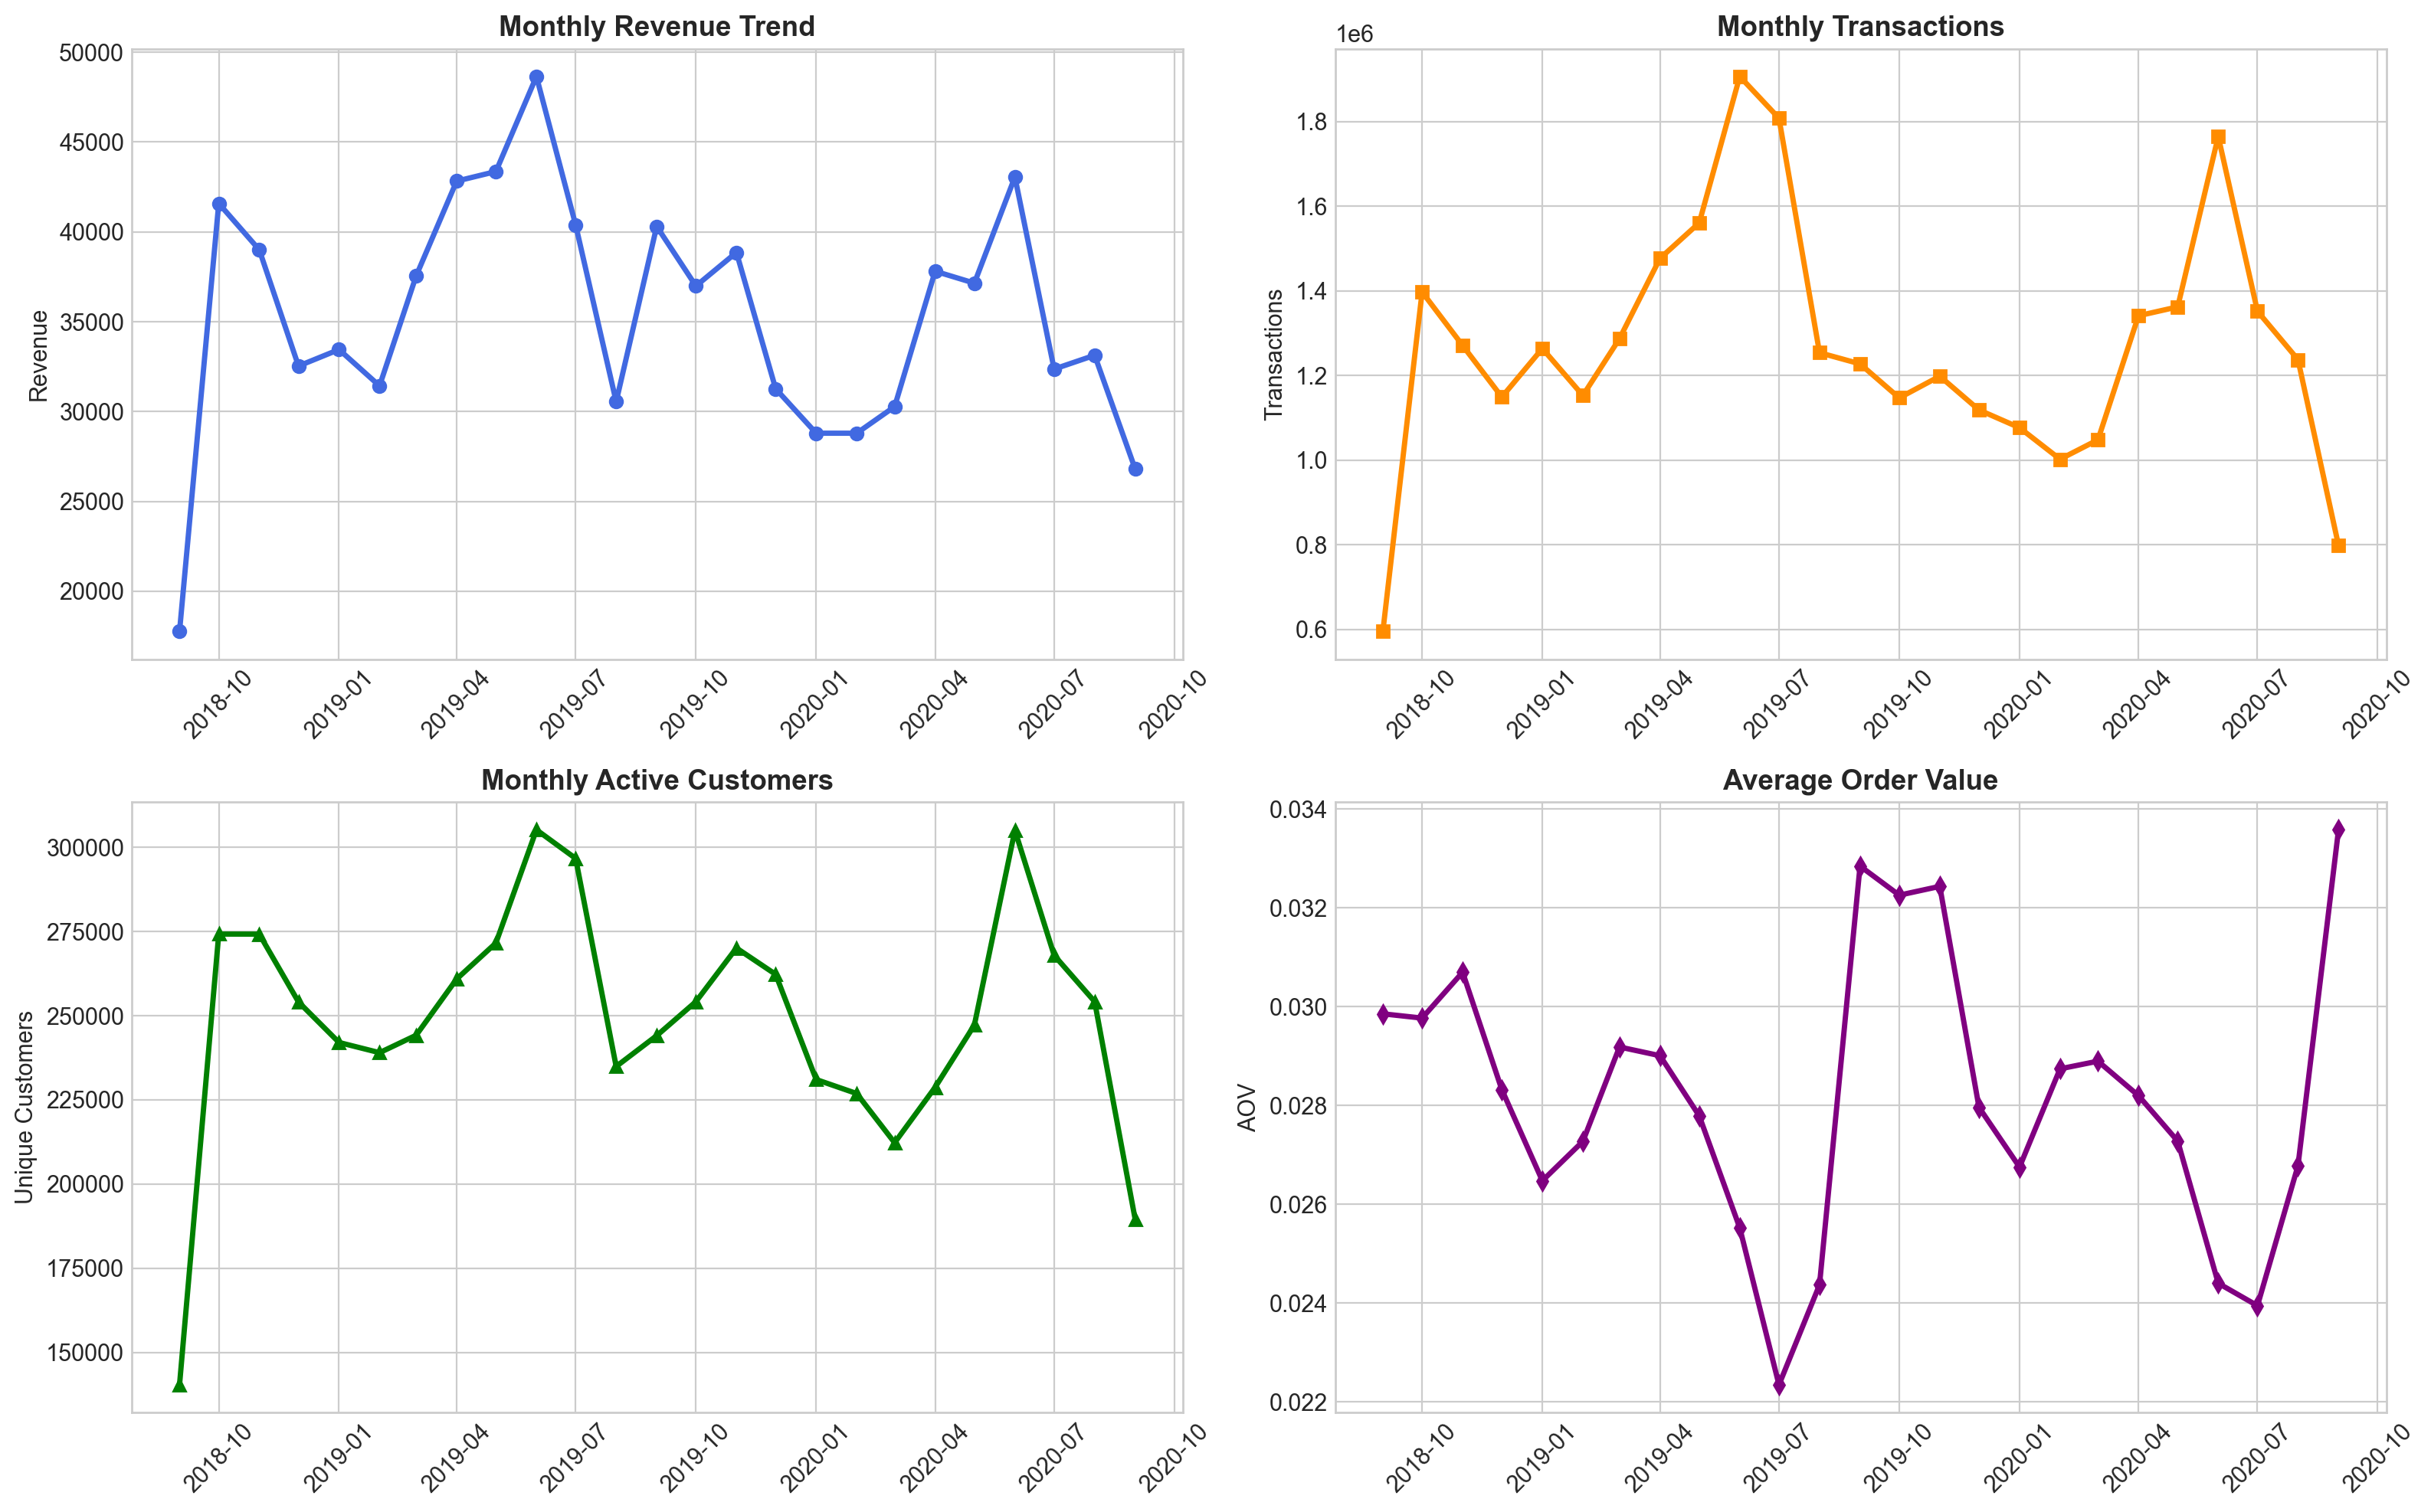


 Revenue Growth (First → Last Month): +51.0%
 Peak Revenue Month: June 2019


In [30]:
# ============================================================
# TEMPORAL (MONTHLY) PERFORMANCE ANALYSIS
# ============================================================
print("\n TEMPORAL ANALYSIS")
print("="*70)

monthly_revenue = (
    df.groupby(df['t_dat'].dt.to_period('M'))
    .agg(
        revenue=('price', 'sum'),   # changed from total_purchase
        unique_customers=('customer_id', 'nunique'),
        transactions=('article_id', 'count')
    )
    .reset_index()
)

monthly_revenue['month'] = monthly_revenue['t_dat'].dt.to_timestamp()
monthly_revenue.drop(columns=['t_dat'], inplace=True)

# Average Order Value
monthly_revenue['avg_order_value'] = (
    monthly_revenue['revenue'] / monthly_revenue['transactions']
)

print("\n Monthly Performance (First 5 months):")
display(monthly_revenue.head())


# ------------------------------------------------------------
# Visualization
# ------------------------------------------------------------

fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# 1️⃣ Monthly Revenue
axes[0, 0].plot(monthly_revenue['month'], monthly_revenue['revenue'],
                marker='o', linewidth=2.5, color='royalblue')
axes[0, 0].set_title('Monthly Revenue Trend', fontweight='bold')
axes[0, 0].set_ylabel('Revenue')
axes[0, 0].tick_params(axis='x', rotation=45)

# 2️⃣ Monthly Transactions
axes[0, 1].plot(monthly_revenue['month'], monthly_revenue['transactions'],
                marker='s', linewidth=2.5, color='darkorange')
axes[0, 1].set_title('Monthly Transactions', fontweight='bold')
axes[0, 1].set_ylabel('Transactions')
axes[0, 1].tick_params(axis='x', rotation=45)

# 3️⃣ Monthly Unique Customers
axes[1, 0].plot(monthly_revenue['month'], monthly_revenue['unique_customers'],
                marker='^', linewidth=2.5, color='green')
axes[1, 0].set_title('Monthly Active Customers', fontweight='bold')
axes[1, 0].set_ylabel('Unique Customers')
axes[1, 0].tick_params(axis='x', rotation=45)

# 4️⃣ Average Order Value
axes[1, 1].plot(monthly_revenue['month'], monthly_revenue['avg_order_value'],
                marker='d', linewidth=2.5, color='purple')
axes[1, 1].set_title('Average Order Value', fontweight='bold')
axes[1, 1].set_ylabel('AOV')
axes[1, 1].tick_params(axis='x', rotation=45)

plt.tight_layout()

plt.savefig(FIGURES_PATH / 'revenue_trends.png', dpi=300)

plt.show()


# ------------------------------------------------------------
# Growth & Seasonality Metrics
# ------------------------------------------------------------

revenue_growth = (
    (monthly_revenue['revenue'].iloc[-1] /
     monthly_revenue['revenue'].iloc[0]) - 1
) * 100

print(f"\n Revenue Growth (First → Last Month): {revenue_growth:+.1f}%")

peak_month = monthly_revenue.loc[
    monthly_revenue['revenue'].idxmax(), 'month'
]

print(f" Peak Revenue Month: {peak_month.strftime('%B %Y')}")


 SALES CHANNEL ANALYSIS

 Channel Performance:


,Transactions,Total_Revenue,Unique_Customers,Avg_Order_Value,Revenue_per_Customer,Trans_per_Customer
channel_name,,,,,,
Online,22379862,668963.15,1108418,0.03,0.60,20.19
Store,9408462,215682.83,737118,0.02,0.29,12.76


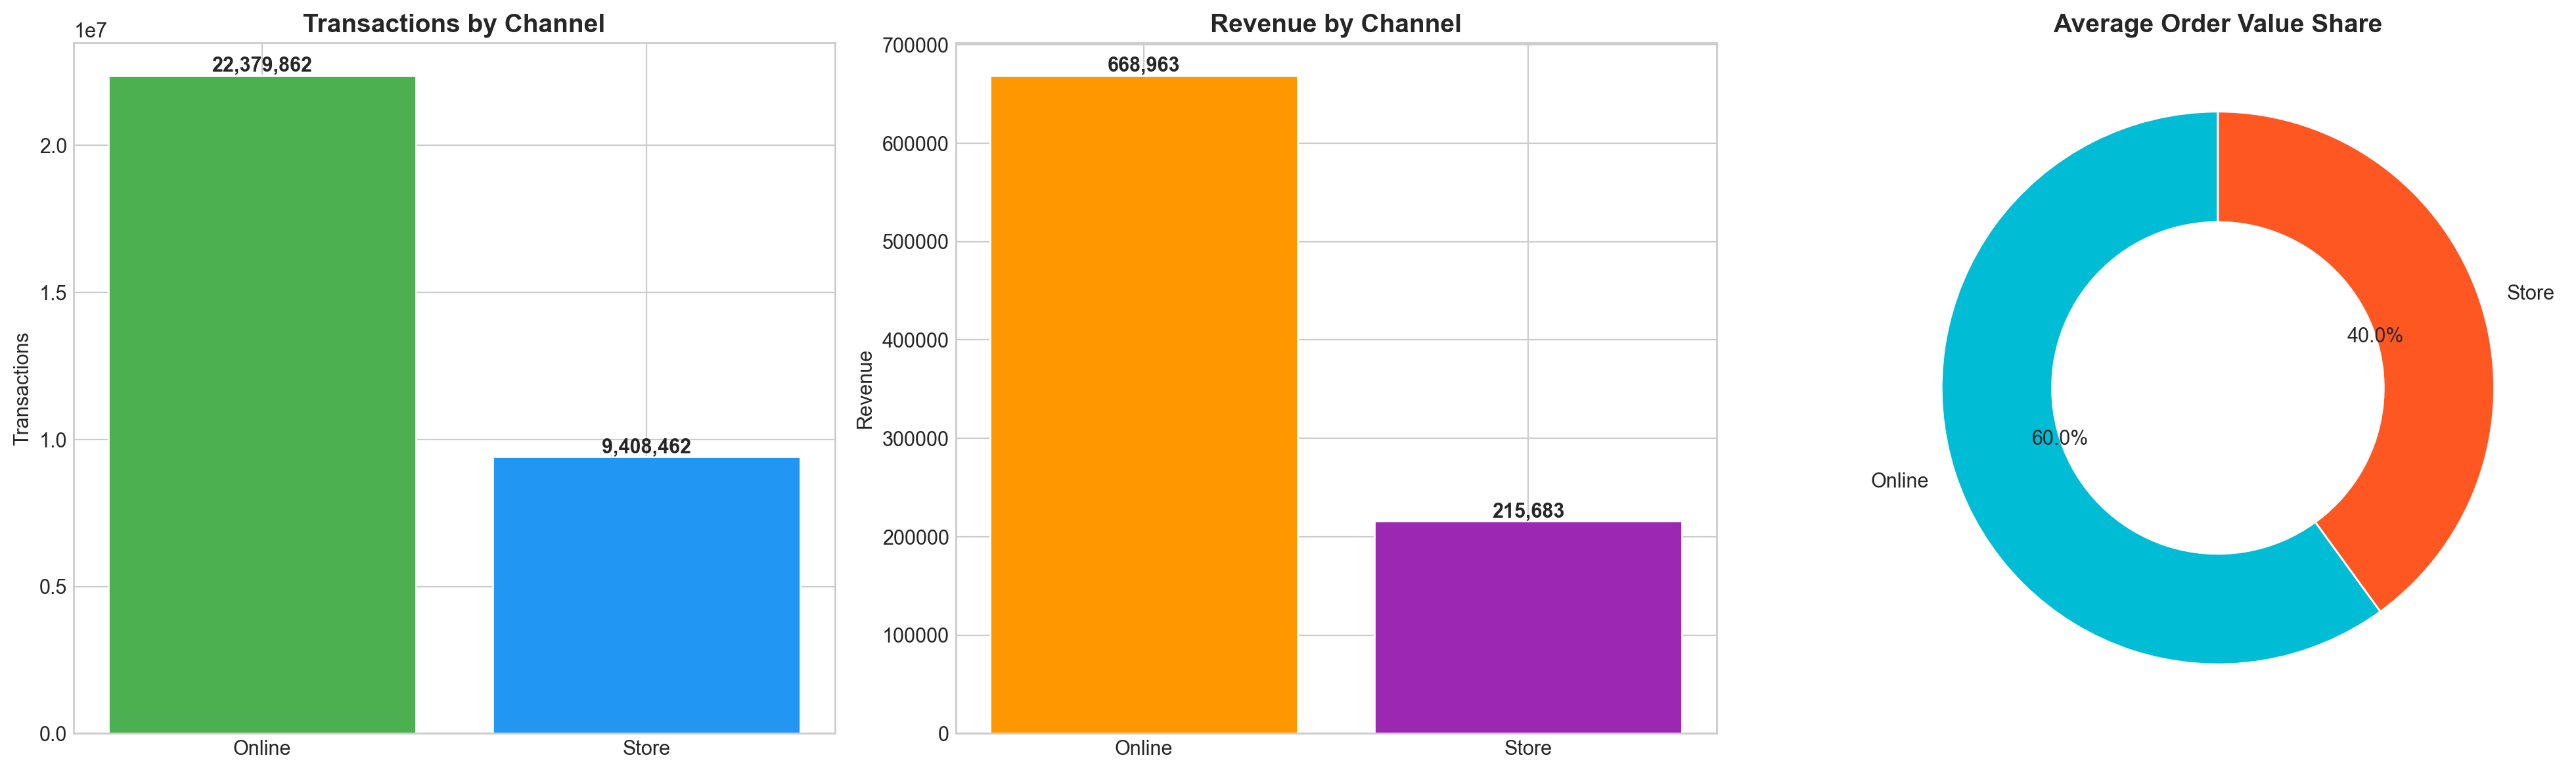


 Online represents 70.4% of transactions


In [31]:
# ============================================================
# SALES CHANNEL ANALYSIS
# ============================================================

print("\n SALES CHANNEL ANALYSIS")
print("="*70)

# Ensure sales_channel_id exists
if "sales_channel_id" not in df.columns:
    print(" sales_channel_id column not found in dataset.")
else:

    # Map channel IDs
    channel_mapping = {1: 'Store', 2: 'Online'}
    df['channel_name'] = df['sales_channel_id'].map(channel_mapping)

    # Aggregate metrics
    channel_analysis = (
        df.groupby('channel_name')
        .agg(
            Transactions=('article_id', 'count'),
            Total_Revenue=('price', 'sum'),
            Unique_Customers=('customer_id', 'nunique')
        )
        .round(2)
    )

    # Derived KPIs
    channel_analysis['Avg_Order_Value'] = (
        channel_analysis['Total_Revenue'] /
        channel_analysis['Transactions']
    ).round(2)

    channel_analysis['Revenue_per_Customer'] = (
        channel_analysis['Total_Revenue'] /
        channel_analysis['Unique_Customers']
    ).round(2)

    channel_analysis['Trans_per_Customer'] = (
        channel_analysis['Transactions'] /
        channel_analysis['Unique_Customers']
    ).round(2)

    print("\n Channel Performance:")
    display(channel_analysis)

    # ------------------------------------------------------------
    # Visualization
    # ------------------------------------------------------------
import seaborn as sns

sns.set_style("whitegrid")

fig, axes = plt.subplots(1, 3, figsize=(20, 6))

colors = ["#4CAF50", "#2196F3"]

# 1️ Transactions by Channel
bars1 = axes[0].bar(
    channel_analysis.index,
    channel_analysis['Transactions'],
    color=colors
)

axes[0].set_title("Transactions by Channel", fontsize=14, fontweight='bold')
axes[0].set_ylabel("Transactions")

# Add value labels
for bar in bars1:
    height = bar.get_height()
    axes[0].text(
        bar.get_x() + bar.get_width()/2,
        height,
        f'{int(height):,}',
        ha='center',
        va='bottom',
        fontweight='bold'
    )


# 2️ Revenue by Channel
bars2 = axes[1].bar(
    channel_analysis.index,
    channel_analysis['Total_Revenue'],
    color=["#FF9800", "#9C27B0"]
)

axes[1].set_title("Revenue by Channel", fontsize=14, fontweight='bold')
axes[1].set_ylabel("Revenue")

for bar in bars2:
    height = bar.get_height()
    axes[1].text(
        bar.get_x() + bar.get_width()/2,
        height,
        f'{height:,.0f}',
        ha='center',
        va='bottom',
        fontweight='bold'
    )


# 3️ AOV Comparison (Donut Chart)
axes[2].pie(
    channel_analysis['Avg_Order_Value'],
    labels=channel_analysis.index,
    autopct='%1.1f%%',
    startangle=90,
    colors=["#00BCD4", "#FF5722"],
    wedgeprops=dict(width=0.4)
)

axes[2].set_title("Average Order Value Share", fontsize=14, fontweight='bold')


plt.tight_layout()

plt.savefig(FIGURES_PATH / "channel_comparison.png", dpi=300)

plt.show()

    # ------------------------------------------------------------
    # Insight Metric
    # ------------------------------------------------------------

online_pct = (
    channel_analysis.loc['Online', 'Transactions'] /
    channel_analysis['Transactions'].sum()
) * 100

print(f"\n Online represents {online_pct:.1f}% of transactions")


 PRICE DISTRIBUTION ANALYSIS


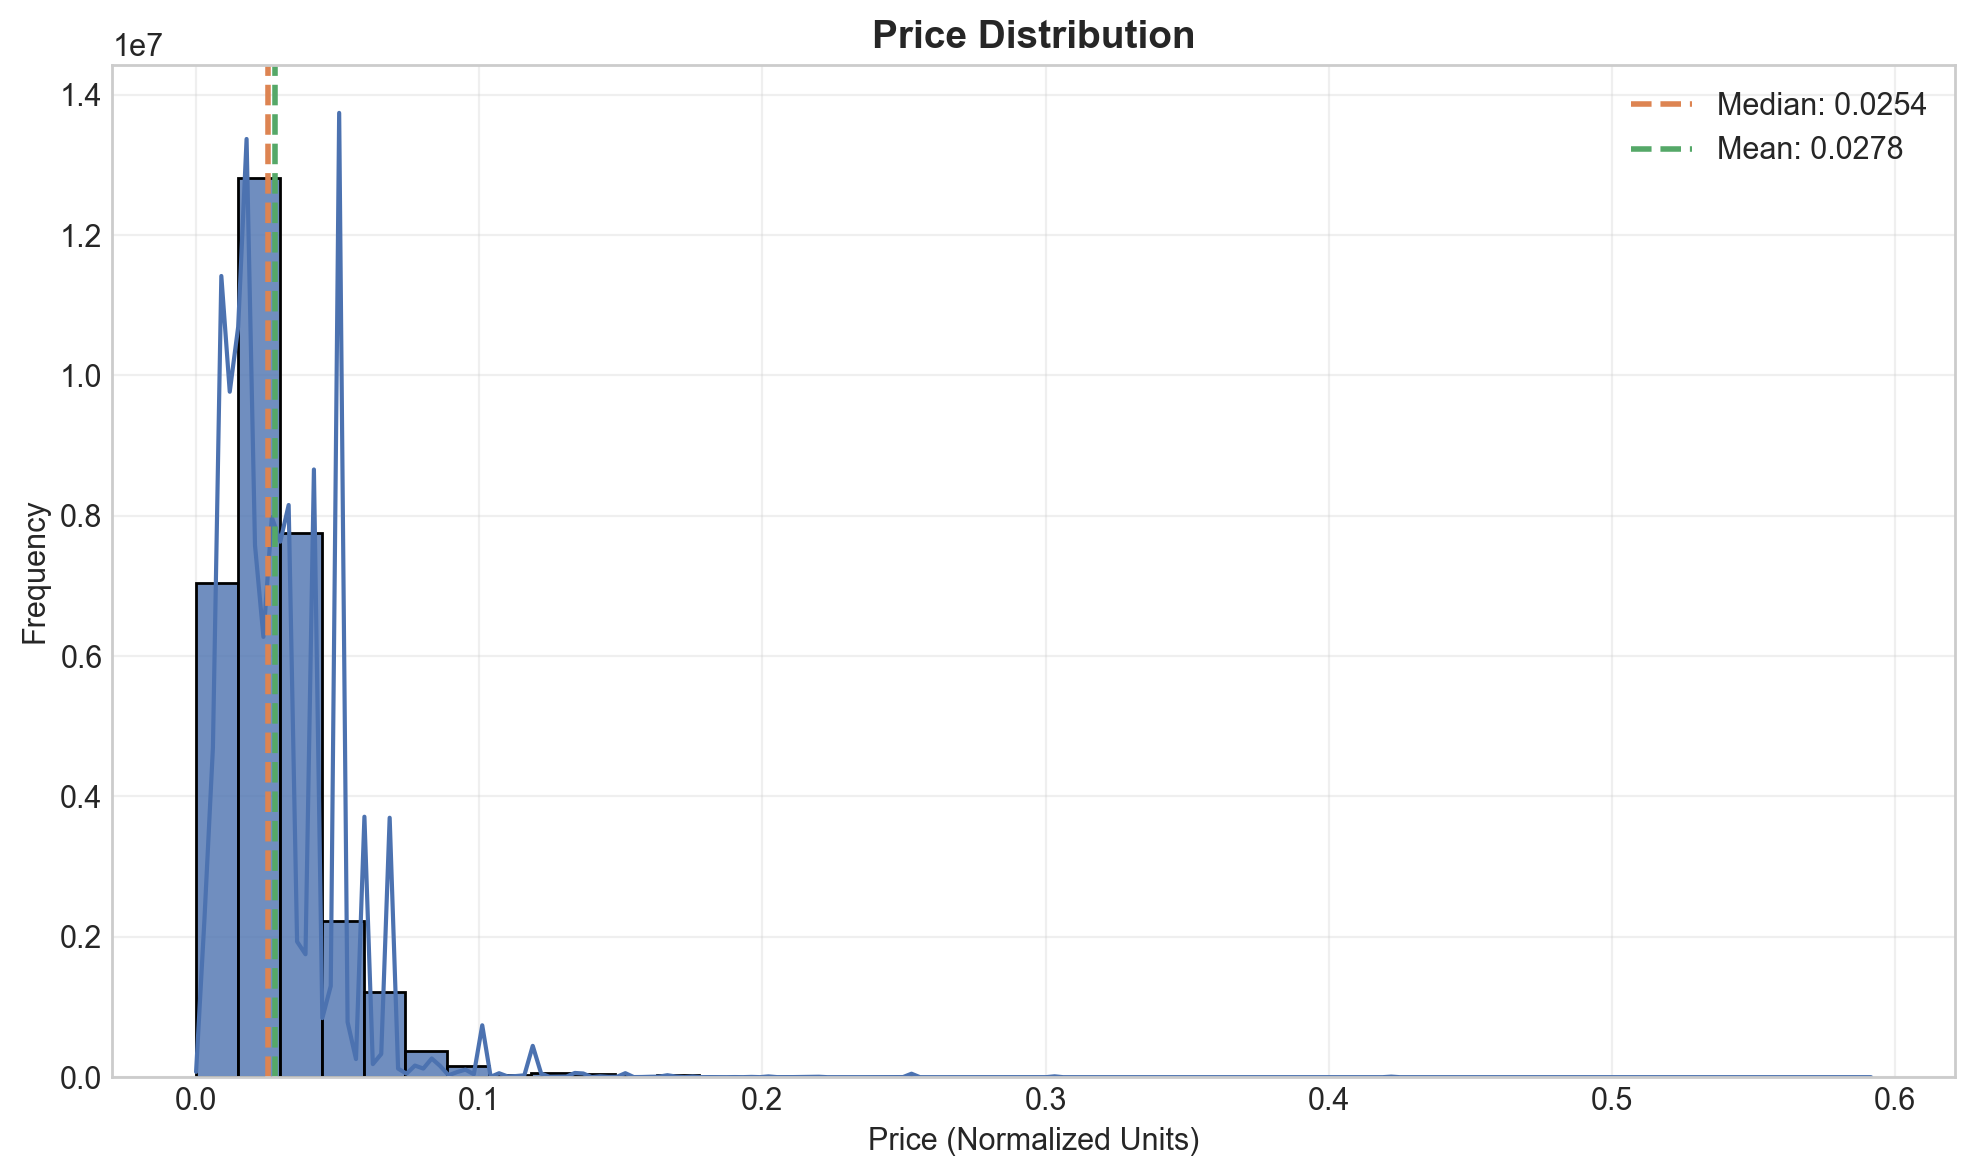


Median Price: 0.0254
Mean Price: 0.0278
Skewness: 3.11


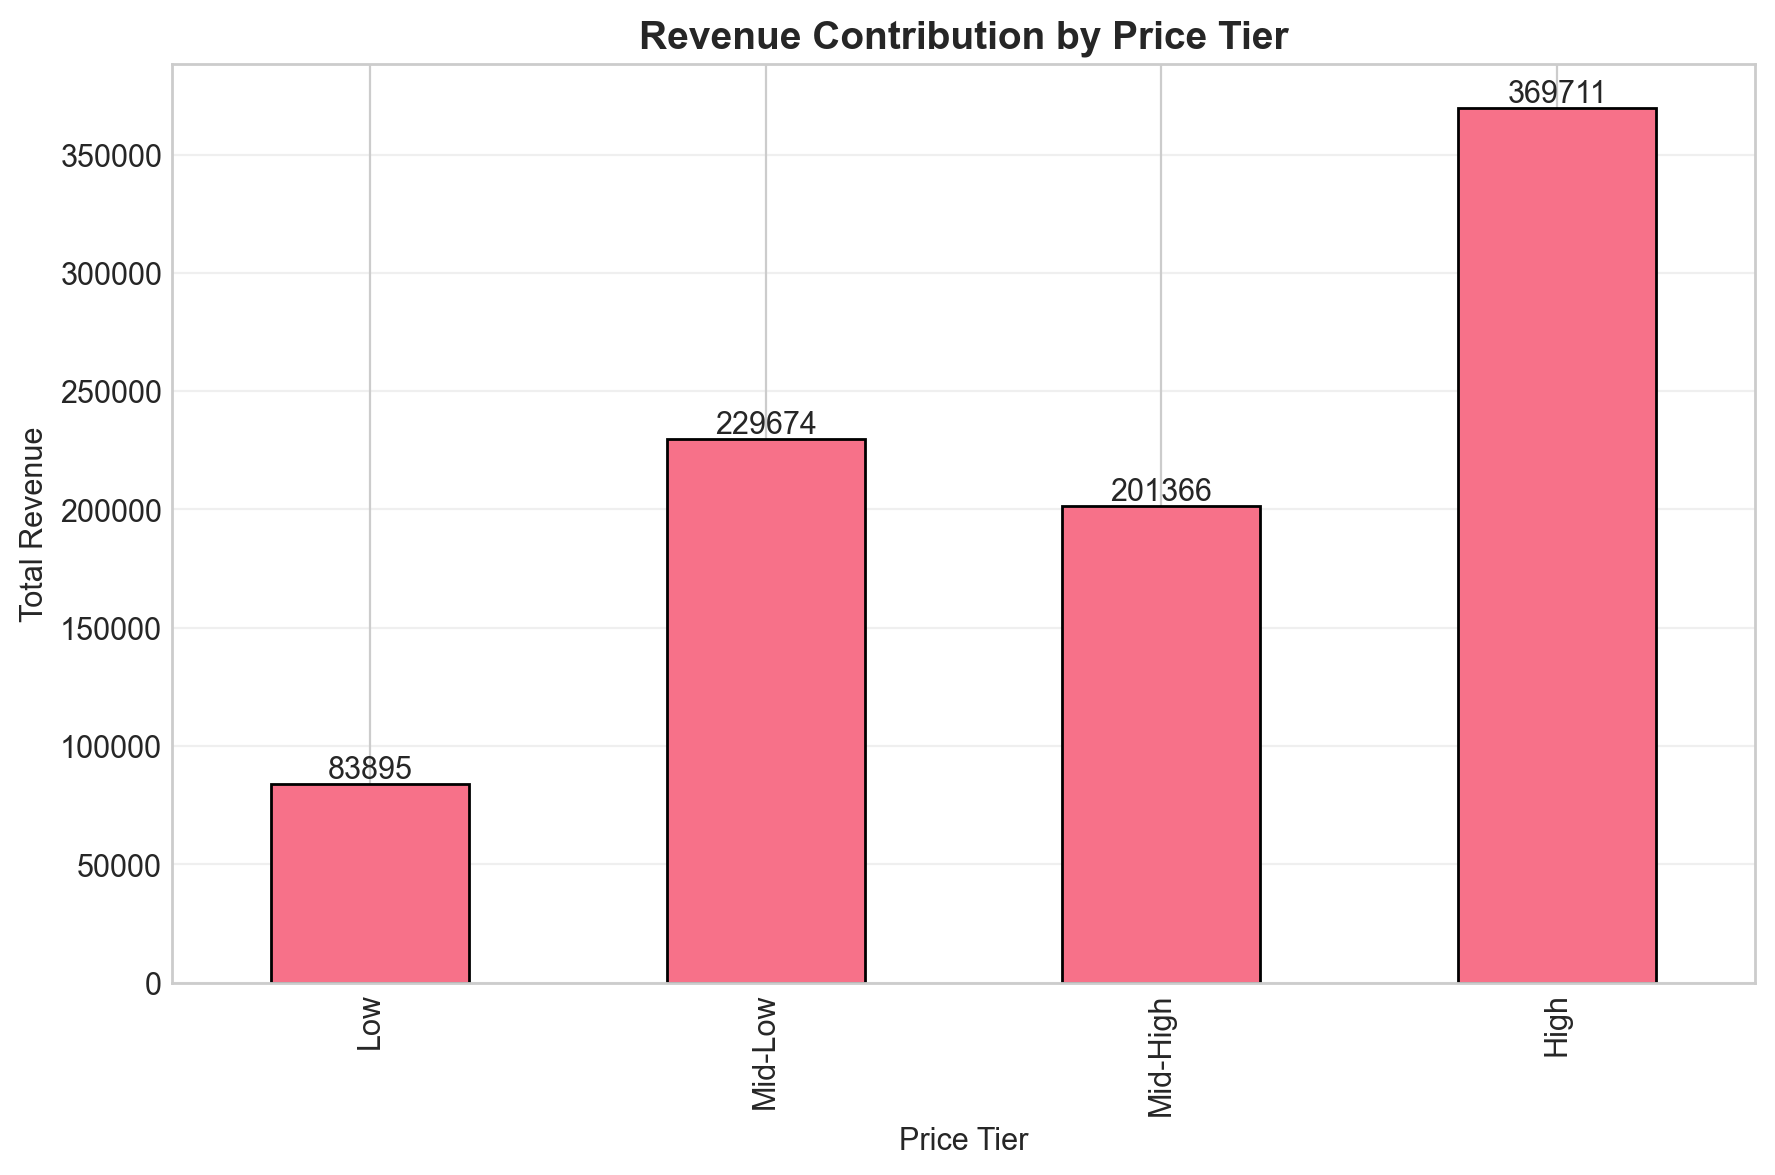


 Revenue Share by Price Tier:
price_tier
Low         9.48
Mid-Low    25.96
Mid-High   22.76
High       41.79
Name: price, dtype: float64


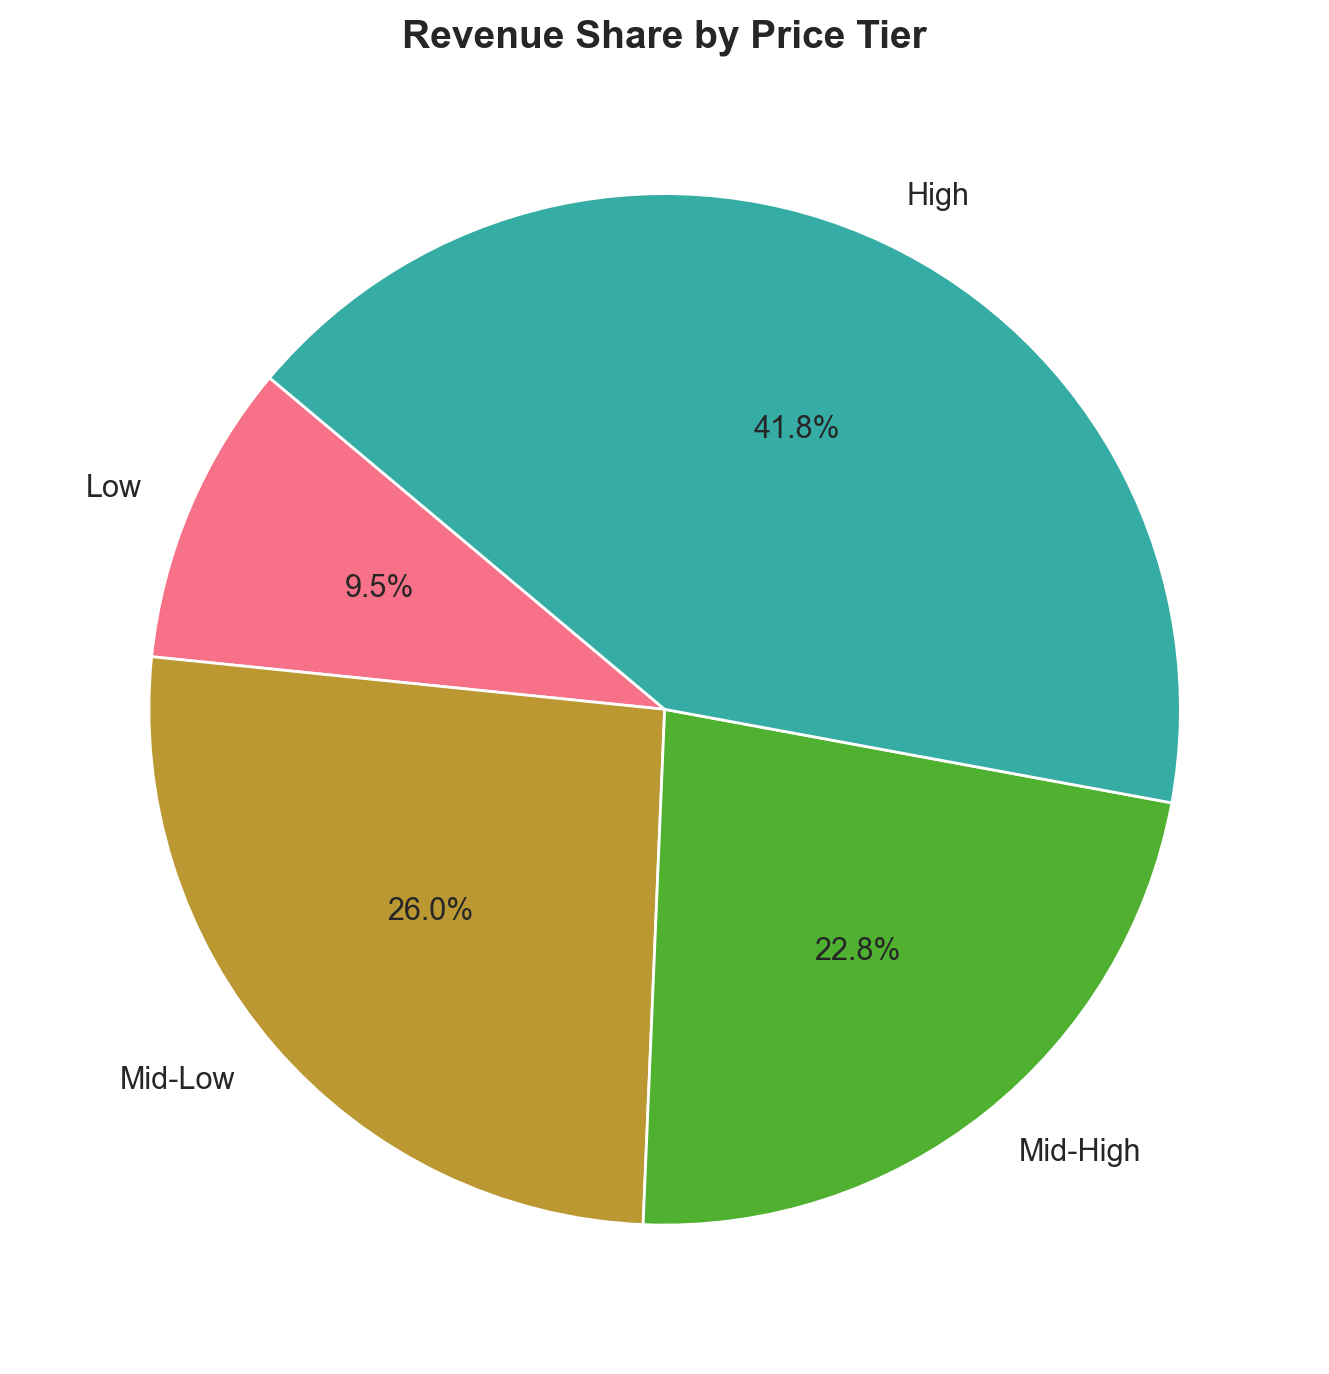

In [32]:
print("\n PRICE DISTRIBUTION ANALYSIS")
print("="*70)

sns.set_style("whitegrid")

# ------------------------------------------------------------
# 1️⃣ Price Distribution Histogram
# ------------------------------------------------------------

plt.figure(figsize=(10,6))

sns.histplot(
    df['price'],
    bins=40,
    kde=True,
    color="#4C72B0",
    edgecolor="black",
    alpha=0.8
)

plt.axvline(
    df['price'].median(),
    color="#DD8452",
    linestyle="--",
    linewidth=2,
    label=f"Median: {df['price'].median():.4f}"
)

plt.axvline(
    df['price'].mean(),
    color="#55A868",
    linestyle="--",
    linewidth=2,
    label=f"Mean: {df['price'].mean():.4f}"
)

plt.title("Price Distribution", fontsize=14, fontweight="bold")
plt.xlabel("Price (Normalized Units)", fontsize=11)
plt.ylabel("Frequency", fontsize=11)

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(FIGURES_PATH / "price_distribution_clean.png", dpi=300)
plt.show()

print(f"\nMedian Price: {df['price'].median():.4f}")
print(f"Mean Price: {df['price'].mean():.4f}")
print(f"Skewness: {df['price'].skew():.2f}")

# ------------------------------------------------------------
# 2️⃣ Revenue by Price Tier
# ------------------------------------------------------------

df["price_tier"] = pd.qcut(
    df["price"],
    q=4,
    labels=["Low", "Mid-Low", "Mid-High", "High"]
)

tier_revenue = df.groupby("price_tier")["price"].sum()

plt.figure(figsize=(9,6))

bars = tier_revenue.plot(
    kind="bar",
    edgecolor="black"
)

plt.title("Revenue Contribution by Price Tier", fontsize=14, fontweight="bold")
plt.xlabel("Price Tier")
plt.ylabel("Total Revenue")

plt.grid(axis="y", alpha=0.3)

# Add value labels on bars
for i, value in enumerate(tier_revenue):
    plt.text(i, value, f"{value:.0f}", ha='center', va='bottom')

plt.tight_layout()
plt.savefig(FIGURES_PATH / "price_tier_revenue.png", dpi=300)
plt.show()

# ------------------------------------------------------------
# 3️⃣ Revenue Share Percentage
# ------------------------------------------------------------

tier_pct = (tier_revenue / tier_revenue.sum() * 100).round(2)

print("\n Revenue Share by Price Tier:")
print(tier_pct)

# ------------------------------------------------------------
# 4️⃣ Pie Chart (NEW - Better Business Visualization)
# ------------------------------------------------------------

plt.figure(figsize=(7,7))

plt.pie(
    tier_revenue,
    labels=tier_revenue.index,
    autopct='%1.1f%%',
    startangle=140
)

plt.title("Revenue Share by Price Tier", fontsize=14, fontweight="bold")

plt.tight_layout()
plt.savefig(FIGURES_PATH / "price_tier_share.png", dpi=300)
plt.show()

In [33]:
# ============================================================
# PRODUCT & CATEGORY PERFORMANCE ANALYSIS
# ============================================================

print("\n PRODUCT PERFORMANCE ANALYSIS")
print("="*70)

# ------------------------------------------------------------
# 1️⃣ Top Products by Revenue
# ------------------------------------------------------------

top_products = (
    df.groupby('article_id')
    .agg(
        total_revenue=('price', 'sum'),
        units_sold=('article_id', 'count'),
        avg_price=('price', 'mean')
    )
    .round(4)
    .sort_values('total_revenue', ascending=False)
    .head(20)
)

print("\nTop 10 Products by Revenue:")
display(top_products.head(10))

# ------------------------------------------------------------
# 2️⃣ Category Performance (Revenue Drivers)
# ------------------------------------------------------------

if 'product_group_name' in df.columns:

    category_performance = (
        df.groupby('product_group_name')
        .agg(
            total_revenue=('price', 'sum'),
            transactions=('article_id', 'count'),
            avg_price=('price', 'mean')
        )
        .round(4)
        .sort_values('total_revenue', ascending=False)
    )

    print("\nTop 10 Categories by Revenue:")
    display(category_performance.head(10))

    # ------------------------------------------------------------
    # Visualization (Cleaner & Presentation Ready)
    # ------------------------------------------------------------

    plt.figure(figsize=(8,6))

    category_performance.head(10)['total_revenue'] \
        .sort_values() \
        .plot(kind='barh')

    plt.title("Top 10 Revenue-Generating Categories")
    plt.xlabel("Total Revenue")
    plt.ylabel("")
    plt.tight_layout()
    plt.savefig(FIGURES_PATH / 'top_categories_revenue.png', dpi=300)
    plt.show()

    # ------------------------------------------------------------
    # Revenue Share %
    # ------------------------------------------------------------

    category_pct = (
        category_performance['total_revenue'] /
        category_performance['total_revenue'].sum() * 100
    ).round(2)

    print("\n Revenue Share by Category (Top 5):")
    print(category_pct.head(5))


 PRODUCT PERFORMANCE ANALYSIS

Top 10 Products by Revenue:


,total_revenue,units_sold,avg_price
article_id,,,
706016001,1631.73,50287,0.03
706016002,1136.32,35043,0.03
568601006,939.27,19379,0.05
448509014,781.48,19216,0.04
706016003,692.20,21241,0.03
399223001,686.48,22236,0.03
720125001,683.61,21063,0.03
562245046,656.21,20719,0.03
751471001,590.64,18263,0.03



 CUSTOMER BEHAVIOR PATTERNS

 Customer Statistics Summary:


,total_spend,avg_order,num_orders,first_purchase,last_purchase,days_active
count,1362281.00,1362281.00,1362281.00,1362281,1362281,1362281.00
mean,0.65,0.03,23.33,2019-05-02 11:03:35.778389760,2020-01-30 20:26:15.037162240,273.39
min,0.00,0.00,1.00,2018-09-20 00:00:00,2018-09-20 00:00:00,0.00
25%,0.09,0.02,3.00,2018-10-29 00:00:00,2019-08-21 00:00:00,0.00
50%,0.25,0.03,9.00,2019-02-16 00:00:00,2020-04-24 00:00:00,206.00
75%,0.70,0.03,27.00,2019-10-03 00:00:00,2020-08-05 00:00:00,549.00
max,57.68,0.51,1895.00,2020-09-22 00:00:00,2020-09-22 00:00:00,733.00
std,1.20,0.01,39.24,NaN,NaN,269.96


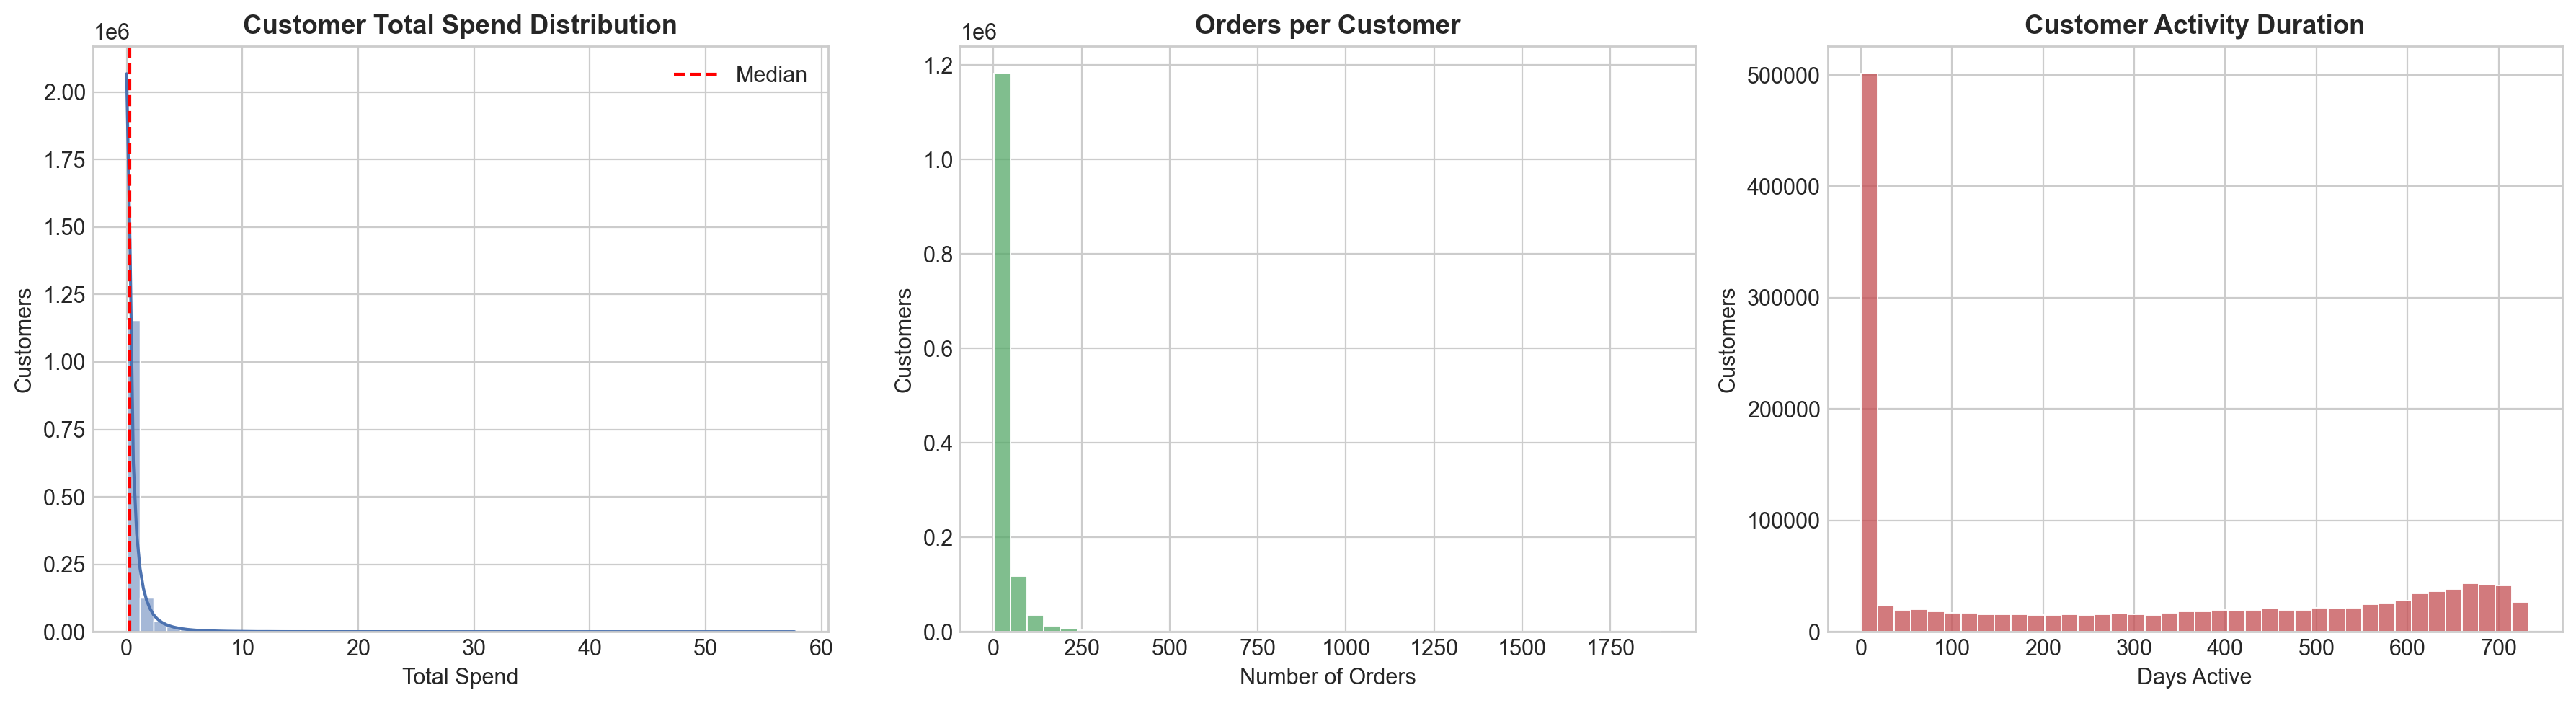


 PARETO ANALYSIS (Revenue Concentration)
----------------------------------------------------------------------
Top 29.41% of customers generate 80% of revenue
400,586 out of 1,362,281 customers


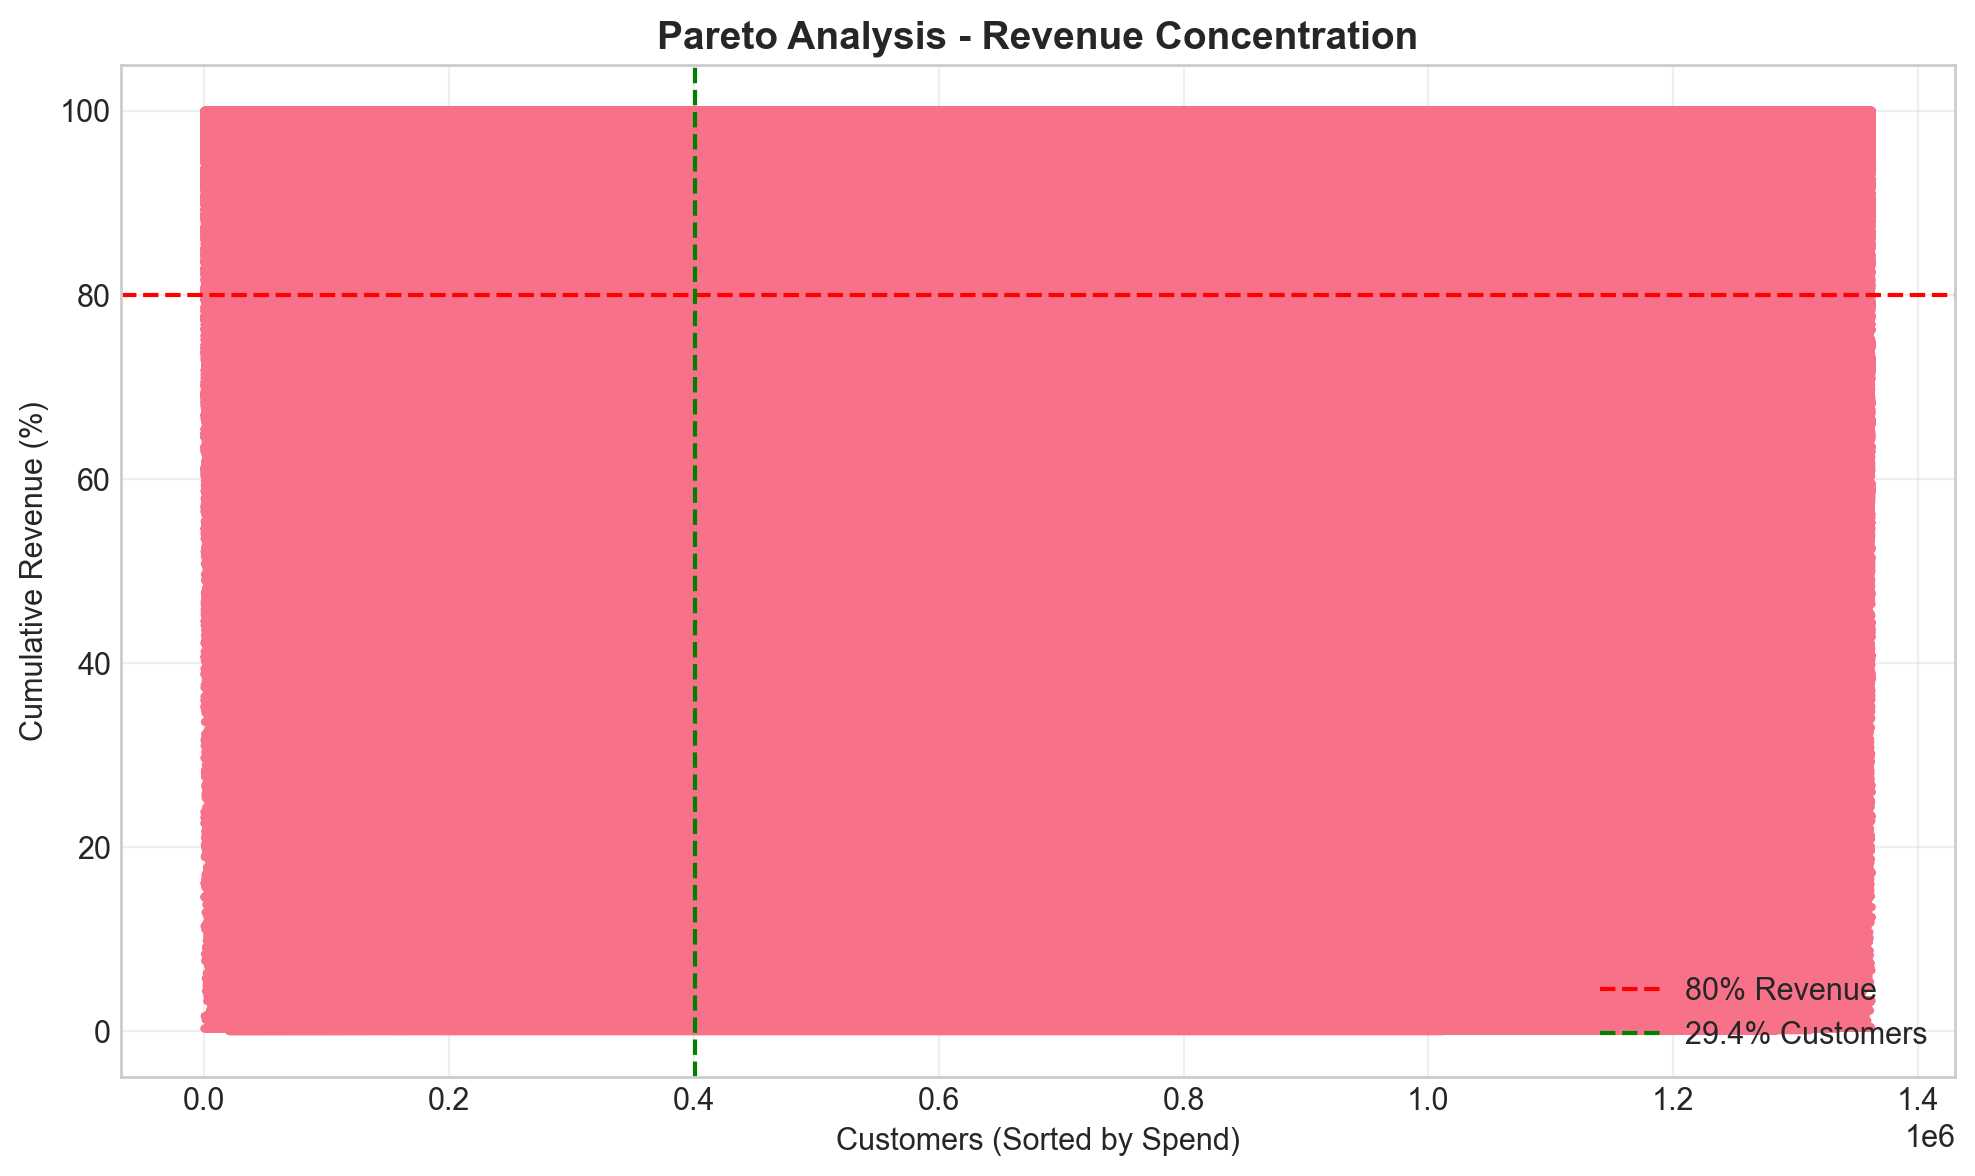

In [34]:
# ============================================================
# CUSTOMER BEHAVIOR ANALYSIS
# ============================================================

print("\n CUSTOMER BEHAVIOR PATTERNS")
print("="*70)

sns.set_style("whitegrid")

# ------------------------------------------------------------
# 1️⃣ Customer Aggregation
# ------------------------------------------------------------

customer_stats = (
    df.groupby('customer_id')
    .agg(
        total_spend=('price', 'sum'),
        avg_order=('price', 'mean'),
        num_orders=('article_id', 'count'),
        first_purchase=('t_dat', 'min'),
        last_purchase=('t_dat', 'max')
    )
    .reset_index()
)

customer_stats['days_active'] = (
    customer_stats['last_purchase'] -
    customer_stats['first_purchase']
).dt.days

print("\n Customer Statistics Summary:")
display(customer_stats.describe())

# ------------------------------------------------------------
# 2️⃣ Customer Behavior Dashboard (3 Visuals)
# ------------------------------------------------------------

fig, axes = plt.subplots(1, 3, figsize=(18,5))

# Total Spend Distribution
sns.histplot(
    customer_stats['total_spend'],
    bins=50,
    kde=True,
    color="#4C72B0",
    ax=axes[0]
)

axes[0].axvline(
    customer_stats['total_spend'].median(),
    color="red",
    linestyle="--",
    label="Median"
)

axes[0].set_title("Customer Total Spend Distribution", fontweight="bold")
axes[0].set_xlabel("Total Spend")
axes[0].set_ylabel("Customers")
axes[0].legend()

# Number of Orders Distribution
sns.histplot(
    customer_stats['num_orders'],
    bins=40,
    color="#55A868",
    ax=axes[1]
)

axes[1].set_title("Orders per Customer", fontweight="bold")
axes[1].set_xlabel("Number of Orders")
axes[1].set_ylabel("Customers")

# Customer Tenure
sns.histplot(
    customer_stats['days_active'],
    bins=40,
    color="#C44E52",
    ax=axes[2]
)

axes[2].set_title("Customer Activity Duration", fontweight="bold")
axes[2].set_xlabel("Days Active")
axes[2].set_ylabel("Customers")

plt.tight_layout()
plt.savefig(FIGURES_PATH / "customer_behavior_dashboard.png", dpi=300)
plt.show()

# ------------------------------------------------------------
# 3️⃣ Pareto (80/20) Analysis
# ------------------------------------------------------------

customer_stats_sorted = customer_stats.sort_values(
    'total_spend', ascending=False
)

customer_stats_sorted['cumulative_revenue'] = \
    customer_stats_sorted['total_spend'].cumsum()

customer_stats_sorted['cumulative_pct'] = (
    customer_stats_sorted['cumulative_revenue'] /
    customer_stats_sorted['total_spend'].sum()
) * 100

pct_80_customers = (
    customer_stats_sorted['cumulative_pct'] <= 80
).sum()

pct_80_customers_pct = (
    pct_80_customers / len(customer_stats_sorted) * 100
)

print("\n PARETO ANALYSIS (Revenue Concentration)")
print("-"*70)
print(f"Top {pct_80_customers_pct:.2f}% of customers generate 80% of revenue")
print(f"{pct_80_customers:,} out of {len(customer_stats_sorted):,} customers")

# ------------------------------------------------------------
# 4️⃣ Professional Pareto Curve
# ------------------------------------------------------------

plt.figure(figsize=(10,6))

plt.plot(
    customer_stats_sorted['cumulative_pct'],
    linewidth=3
)

plt.axhline(
    80,
    color="red",
    linestyle="--",
    label="80% Revenue"
)

plt.axvline(
    pct_80_customers,
    color="green",
    linestyle="--",
    label=f"{pct_80_customers_pct:.1f}% Customers"
)

plt.title("Pareto Analysis - Revenue Concentration", fontsize=14, fontweight="bold")
plt.xlabel("Customers (Sorted by Spend)")
plt.ylabel("Cumulative Revenue (%)")

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(FIGURES_PATH / "pareto_curve.png", dpi=300)
plt.show()

In [35]:
# ============================================================
# DEMOGRAPHIC ANALYSIS (AGE SEGMENTATION)
# ============================================================

if 'age' in df.columns:

    print("\n DEMOGRAPHIC ANALYSIS")
    print("="*70)

    age_data = df[df['age'].notna()].copy()

    if len(age_data) > 0:

        # Define age groups (cleaner bins)
        age_data['age_group'] = pd.cut(
            age_data['age'],
            bins=[15, 25, 35, 45, 55, 100],
            labels=['18-25', '26-35', '36-45', '46-55', '55+']
        )

        # Aggregate KPIs
        age_analysis = (
            age_data.groupby('age_group')
            .agg(
                total_revenue=('total_purchase', 'sum'),
                avg_order=('total_purchase', 'mean'),
                transactions=('article_id', 'count'),
                unique_customers=('customer_id', 'nunique')
            )
            .round(4)
        )

        # Revenue share %
        age_analysis['revenue_share_%'] = (
            age_analysis['total_revenue'] /
            age_analysis['total_revenue'].sum() * 100
        ).round(2)

        print(f"\n Age Group Analysis "
              f"(Coverage: {len(age_data)/len(df)*100:.1f}% of transactions)\n")

        display(age_analysis)

        # ------------------------------------------------------------
        # Visualization (Clean Version)
        # ------------------------------------------------------------

        plt.figure(figsize=(8,5))
        age_analysis['total_revenue'] \
            .sort_values() \
            .plot(kind='barh')

        plt.title("Revenue by Age Group")
        plt.xlabel("Total Revenue")
        plt.ylabel("Age Group")
        plt.tight_layout()
        plt.savefig(FIGURES_PATH / 'age_revenue.png', dpi=300)
        plt.show()

        # ------------------------------------------------------------
        # Strategic Insight
        # ------------------------------------------------------------

        top_age = age_analysis['total_revenue'].idxmax()
        top_share = age_analysis.loc[top_age, 'revenue_share_%']

        print(f"\n Highest Revenue Segment: {top_age}")
        print(f"Contributes {top_share:.2f}% of total revenue")

    else:
        print("⚠️ No valid age data available")

else:
    print("\n⚠️ Age data not available in dataset")


⚠️ Age data not available in dataset



 TIME-BASED PURCHASE PATTERNS

 Purchase Patterns by Day of Week:



,revenue,transactions,avg_order,revenue_share_%
day_of_week,,,,
Monday,114883.80,4054054,0.03,12.99
Tuesday,119471.79,4198630,0.03,13.51
Wednesday,133354.51,4842821,0.03,15.07
Thursday,135167.94,4860595,0.03,15.28
Friday,130138.64,4749132,0.03,14.71
Saturday,137059.13,5049500,0.03,15.49
Sunday,114570.17,4033592,0.03,12.95


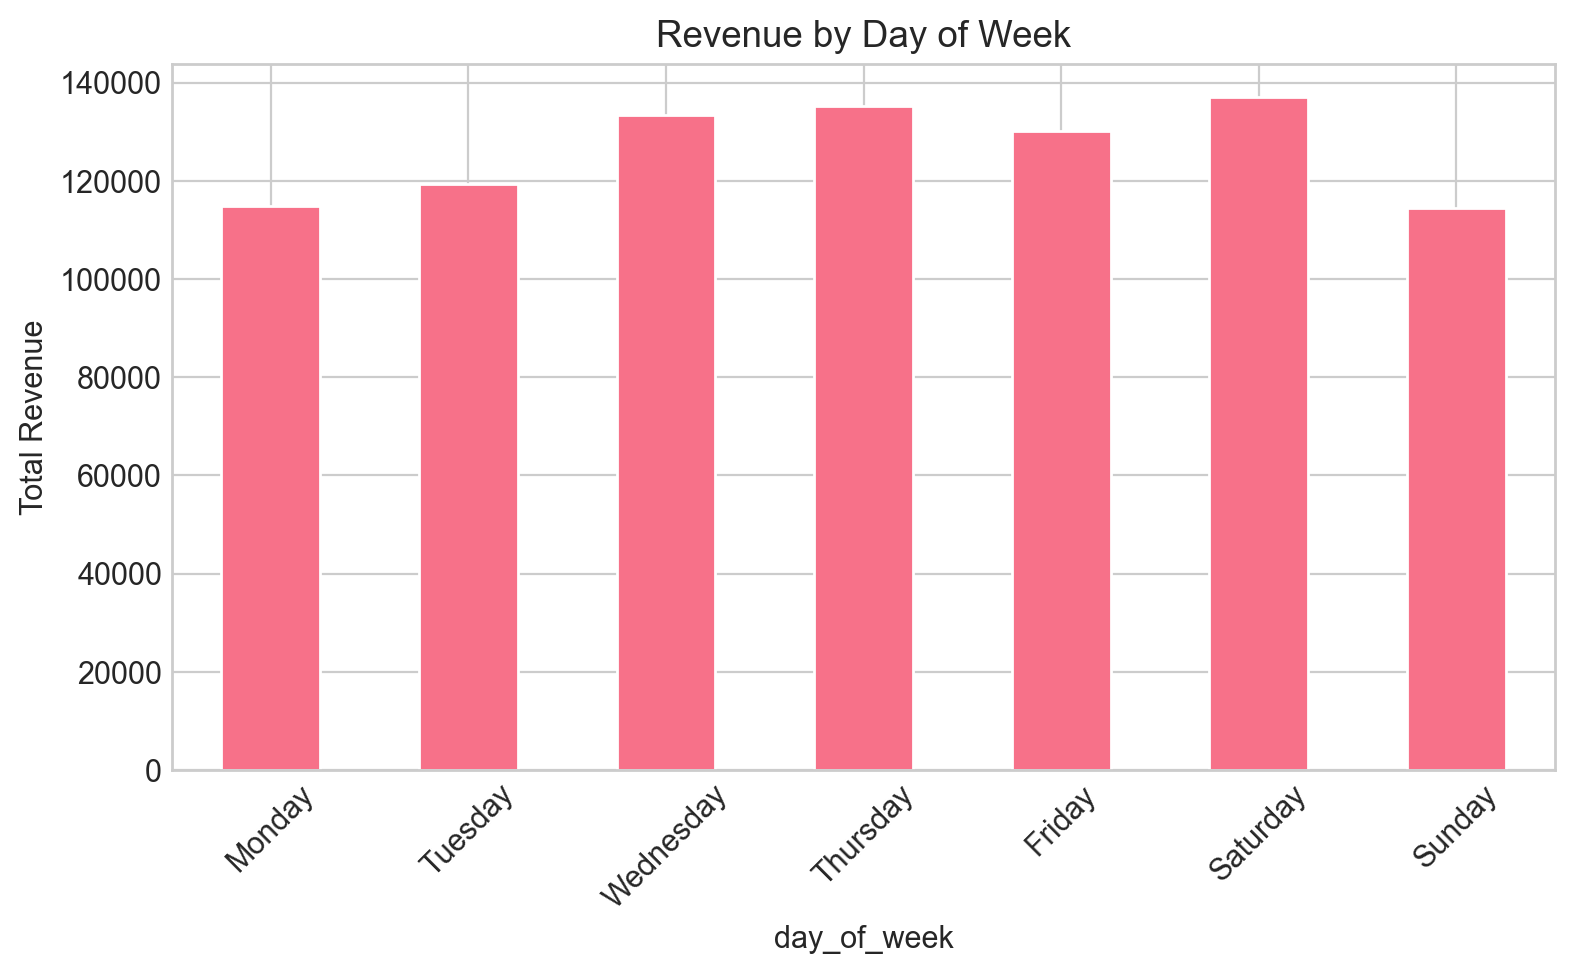


 Weekend vs Weekday Performance:



,revenue,transactions,avg_order,revenue_share_%
Weekday,633016.68,22705232,0.03,71.56
Weekend,251629.29,9083092,0.03,28.44



 Highest Revenue Day: Saturday
Revenue Share: 15.49%


In [36]:
# ============================================================
# TIME-BASED PURCHASE PATTERNS
# ============================================================

print("\n TIME-BASED PURCHASE PATTERNS")
print("="*70)

# Create time features
df['day_of_week'] = df['t_dat'].dt.day_name()
df['is_weekend'] = df['t_dat'].dt.dayofweek.isin([5, 6])

# ------------------------------------------------------------
# 1️⃣ Day of Week Analysis
# ------------------------------------------------------------

dow_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday',
             'Friday', 'Saturday', 'Sunday']

dow_analysis = (
    df.groupby('day_of_week')
    .agg(
        revenue=('price', 'sum'),
        transactions=('article_id', 'count'),
        avg_order=('price', 'mean')
    )
    .round(4)
    .reindex(dow_order)
)

# Revenue share %
dow_analysis['revenue_share_%'] = (
    dow_analysis['revenue'] /
    dow_analysis['revenue'].sum() * 100
).round(2)

print("\n Purchase Patterns by Day of Week:\n")
display(dow_analysis)

# ------------------------------------------------------------
# Visualization (Cleaner)
# ------------------------------------------------------------

plt.figure(figsize=(8,5))
dow_analysis['revenue'].plot(kind='bar')
plt.title("Revenue by Day of Week")
plt.ylabel("Total Revenue")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(FIGURES_PATH / 'day_of_week_revenue.png', dpi=300)
plt.show()

# ------------------------------------------------------------
# 2️⃣ Weekend vs Weekday
# ------------------------------------------------------------

weekend_analysis = (
    df.groupby('is_weekend')
    .agg(
        revenue=('price', 'sum'),
        transactions=('article_id', 'count'),
        avg_order=('price', 'mean')
    )
    .round(4)
)

weekend_analysis.index = ['Weekday', 'Weekend']

weekend_analysis['revenue_share_%'] = (
    weekend_analysis['revenue'] /
    weekend_analysis['revenue'].sum() * 100
).round(2)

print("\n Weekend vs Weekday Performance:\n")
display(weekend_analysis)

# Strategic Insight
top_day = dow_analysis['revenue'].idxmax()
top_day_share = dow_analysis.loc[top_day, 'revenue_share_%']

print(f"\n Highest Revenue Day: {top_day}")
print(f"Revenue Share: {top_day_share:.2f}%")

In [37]:
print("\n" + "="*70)
print(" KEY INSIGHTS FROM EDA")
print("="*70)

insights = []

# ------------------------------------------------------------
# Recalculate core KPIs safely
# ------------------------------------------------------------

total_revenue = df['price'].sum()
total_transactions = len(df)
num_customers = df['customer_id'].nunique()
avg_order_value = df['price'].mean()

# ------------------------------------------------------------
# Insight 1: Revenue scale
# ------------------------------------------------------------

insights.append(
    f"1. REVENUE SCALE: Analyzed {total_revenue:,.2f} total revenue across "
    f"{total_transactions:,} transactions."
)

# ------------------------------------------------------------
# Insight 2: Customer base
# ------------------------------------------------------------

insights.append(
    f"2. CUSTOMER BASE: {num_customers:,} unique customers "
    f"with average {total_transactions/num_customers:.2f} transactions per customer."
)

# ------------------------------------------------------------
# Insight 3: AOV
# ------------------------------------------------------------

insights.append(
    f"3. AVERAGE ORDER VALUE: {avg_order_value:.4f} "
    f"(Median: {df['price'].median():.4f})."
)

# ------------------------------------------------------------
# Insight 4: Channel mix (if exists)
# ------------------------------------------------------------

if 'channel_name' in df.columns:
    online_pct = (df[df['channel_name'] == 'Online'].shape[0] / total_transactions) * 100
    insights.append(
        f"4. CHANNEL MIX: {online_pct:.1f}% Online vs {100-online_pct:.1f}% Store transactions."
    )

# ------------------------------------------------------------
# Insight 5: Pareto principle
# ------------------------------------------------------------

if 'customer_stats_sorted' in locals():
    insights.append(
        f"5. PARETO PRINCIPLE: Top {pct_80_customers_pct:.2f}% of customers "
        f"drive 80% of total revenue."
    )

# ------------------------------------------------------------
# Insight 6: Peak day
# ------------------------------------------------------------

if 'dow_analysis' in locals():
    peak_day = dow_analysis['transactions'].idxmax()
    insights.append(
        f"6. PEAK PURCHASE DAY: {peak_day} shows highest transaction volume."
    )

# ------------------------------------------------------------
# Insight 7: Data quality
# ------------------------------------------------------------

data_completeness = (
    1 - df.isnull().sum().sum() / (len(df) * len(df.columns))
) * 100

insights.append(
    f"7. DATA QUALITY: Dataset is {data_completeness:.2f}% complete."
)

# ------------------------------------------------------------
# Print insights
# ------------------------------------------------------------

for insight in insights:
    print(f"\n{insight}")

# ------------------------------------------------------------
# Save insights
# ------------------------------------------------------------

with open(TABLES_PATH / 'eda_key_insights.txt', 'w') as f:
    f.write("H&M CONSUMER BEHAVIOR - KEY INSIGHTS FROM EDA\n")
    f.write("="*70 + "\n\n")
    for insight in insights:
        f.write(insight + "\n")

print(f"\n Saved: reports/tables/eda_key_insights.txt")


 KEY INSIGHTS FROM EDA

1. REVENUE SCALE: Analyzed 884,645.97 total revenue across 31,788,324 transactions.

2. CUSTOMER BASE: 1,362,281 unique customers with average 23.33 transactions per customer.

3. AVERAGE ORDER VALUE: 0.0278 (Median: 0.0254).

4. CHANNEL MIX: 70.4% Online vs 29.6% Store transactions.

5. PARETO PRINCIPLE: Top 29.41% of customers drive 80% of total revenue.

6. PEAK PURCHASE DAY: Saturday shows highest transaction volume.

7. DATA QUALITY: Dataset is 100.00% complete.

 Saved: reports/tables/eda_key_insights.txt
